# CSCI461 Assignment 1 - Dockerized Data, Text Analysis and Machine Learning

**Dataset:** SMS Spam Collection (UCI Machine Learning Repository, dataset #228)
<https://archive.ics.uci.edu/dataset/228/sms+spam+collection> - licensed CC BY 4.0.

**Pipeline:** Dockerfile -> Custom Image -> Container -> Jupyter -> Data Cleaning -> Sampling -> Text Analysis -> TF-IDF -> Classification + K-Means -> Persistent Outputs -> Docker Hub

This notebook runs inside the custom Docker container. Every file it writes goes to `output/`,
which is bind-mounted to the host so results survive after the container is removed.

| Section | Assignment part |
|---|---|
| 1 | Setup |
| 2 | Dataset understanding |
| 3 | Missing values and duplicates |
| 4 | `loc` / `iloc` |
| 5 | Transformations and feature creation |
| 6 | Sampling (simple random, stratified, cluster) |
| 7 | Correlation of numerical text features |
| 8 | Text analysis |
| 9 | Supervised text classification (TF-IDF + Naive Bayes) |
| 10 | Bonus - model extension (2 classifiers + n-grams + tuning) |
| 11 | K-Means clustering |
| 12 | Save outputs and conclusion |

## 1. Setup

In [1]:
import re
import string
import warnings
from collections import Counter
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
import seaborn as sns
import sklearn

from sklearn.feature_extraction.text import TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.naive_bayes import MultinomialNB
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import MinMaxScaler, Normalizer
from sklearn.decomposition import TruncatedSVD
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, precision_score, recall_score, f1_score,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay,
                             silhouette_score, adjusted_rand_score)

warnings.filterwarnings("ignore", category=FutureWarning)
pd.set_option("display.max_colwidth", 120)
pd.set_option("display.width", 160)
sns.set_theme(style="whitegrid")

RANDOM_STATE = 42
np.random.seed(RANDOM_STATE)

# The notebook may be started from the project root or from notebook/, so find the root.
ROOT = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA_PATH = ROOT / "data" / "dataset.csv"
OUT_DIR = ROOT / "output"
FIG_DIR = OUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

def save_fig(name):
    path = FIG_DIR / name
    plt.savefig(path, dpi=120, bbox_inches="tight")
    print("saved ->", path.relative_to(ROOT))

print("project root :", ROOT)
print("pandas", pd.__version__, "| numpy", np.__version__, "| scikit-learn", sklearn.__version__,
      "| matplotlib", matplotlib.__version__, "| seaborn", sns.__version__)

project root : /tmp/jana
pandas 3.1.0 | numpy 2.5.4 | scikit-learn 1.9.1 | matplotlib 3.11.2 | seaborn 0.13.2


## 2. Dataset understanding

The original UCI file is tab-separated (`label<TAB>message`). It was converted once on the host to
`data/dataset.csv` with two columns: `label` and `message`.

In [2]:
df_raw = pd.read_csv(DATA_PATH, encoding="utf-8")
df_raw.head(10)

,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"
5,spam,FreeMsg Hey there darling it's been 3 week's now and no word back! I'd like some fun you up for it still? Tb ok! XxX...
6,ham,Even my brother is not like to speak with me. They treat me like aids patent.
7,ham,As per your request 'Melle Melle (Oru Minnaminunginte Nurungu Vettam)' has been set as your callertune for all Calle...
8,spam,WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 0906170146...
9,spam,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call Th...


In [3]:
print("shape  :", df_raw.shape)
print("columns:", list(df_raw.columns))
print("\ndtypes:")
print(df_raw.dtypes)

shape  : (5574, 2)
columns: ['label', 'message']

dtypes:
label      str
message    str
dtype: object


In [4]:
df_raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 5574 entries, 0 to 5573
Data columns (total 2 columns):
 #   Column   Non-Null Count  Dtype
---  ------   --------------  -----
 0   label    5574 non-null   str  
 1   message  5574 non-null   str  
dtypes: str(2)
memory usage: 543.0 KB


In [5]:
# Descriptive statistics for the object columns
df_raw.describe(include="all")

,label,message
count,5574,5574
unique,2,5171
top,ham,"Sorry, I'll call later"
freq,4827,30


In [6]:
# Descriptive statistics of message length (the raw data has no numeric column yet)
df_raw["message"].str.len().describe().to_frame("message_char_length")

,message_char_length
count,5574.000000
mean,80.478292
std,59.848302
min,2.000000
25%,36.000000
50%,62.000000
75%,122.000000
max,910.000000


In [7]:
print("Class counts:")
print(df_raw["label"].value_counts())
print("\nClass proportions:")
print(df_raw["label"].value_counts(normalize=True).round(4))

Class counts:
label
ham     4827
spam     747
Name: count, dtype: int64

Class proportions:
label
ham     0.866
spam    0.134
Name: proportion, dtype: float64


**What one row represents:** one SMS message sent to a mobile phone, together with a human label
saying whether it is `spam` (unwanted advertising / scam) or `ham` (a normal, legitimate message).

**Column roles**

| Column | Role | Notes |
|---|---|---|
| `message` | **text** column | Free text of the SMS (raw, unchanged) |
| `label` | **label / category** column | Two classes: `ham`, `spam` - imbalanced (about 87% ham, 13% spam) |
| *(none)* | numerical columns | The raw data has **no** numerical columns. Numerical features such as `char_count`, `word_count`, `unique_word_count`, `avg_word_length`, `digit_count` are created from the text in Section 5. |

## 3. Missing values and duplicates

In [8]:
print("Missing values per column:")
print(df_raw.isna().sum())
blank = df_raw["message"].fillna("").str.strip().eq("").sum()
print("\nEmpty / whitespace-only messages:", blank)
print("Unexpected labels:", sorted(set(df_raw["label"].unique()) - {"ham", "spam"}))

Missing values per column:
label      0
message    0
dtype: int64

Empty / whitespace-only messages: 0
Unexpected labels: []


In [9]:
dup_rows = df_raw.duplicated(keep="first")
dup_msgs = df_raw.duplicated(subset="message", keep="first")
print("Fully duplicated rows (label + message):", dup_rows.sum())
print("Duplicated message text (any label)     :", dup_msgs.sum())

# Same text with different labels would be a labelling conflict
conflicts = df_raw.groupby("message")["label"].nunique()
print("Messages that appear with BOTH labels    :", (conflicts > 1).sum())

print("\nDuplicates by class:")
print(df_raw[dup_rows]["label"].value_counts())
print("\nMost repeated messages:")
df_raw["message"].value_counts().head(5)

Fully duplicated rows (label + message): 403
Duplicated message text (any label)     : 403
Messages that appear with BOTH labels    : 0

Duplicates by class:
label
ham     309
spam     94
Name: count, dtype: int64

Most repeated messages:


message
Sorry, I'll call later                                                                                                                                                                 30
I cant pick the phone right now. Pls send a message                                                                                                                                    12
Ok...                                                                                                                                                                                  10
Please call our customer service representative on FREEPHONE 0808 145 4742 between 9am-11pm as you have WON a guaranteed £1000 cash or £5000 prize!                                     4
Wen ur lovable bcums angry wid u, dnt take it seriously.. Coz being angry is d most childish n true way of showing deep affection, care n luv!.. kettoda manda... Have nice day da.     4
Name: count, dtype: int64

**Treatment and justification**

* **Missing values:** there are no missing values or empty messages, so no imputation is needed.
  The text cleaning function in Section 8 still handles missing text defensively (`NaN` -> `""`).
* **Duplicates:** 403 rows are exact copies (same label and same text): 309 ham - mostly short
  automatic replies such as "Sorry, I'll call later" (30 copies) - and 94 spam from repeated campaigns. We **drop exact duplicates
  and keep the first copy** because:
  1. they over-weight a few messages in word frequencies and statistics;
  2. the same message could land in both the training and the test set, which leaks information and
     makes the classifier look better than it really is;
  3. no message has conflicting labels, so dropping duplicates does not lose any label information.
* Labels are standardised (stripped, lowercase) and whitespace at the ends of messages is removed.

In [10]:
print("Shape BEFORE cleaning:", df_raw.shape)

df = df_raw.copy()
df["label"] = df["label"].str.strip().str.lower()
df["message"] = df["message"].fillna("").str.strip()
df = df[df["message"] != ""]
print("Duplicates after trimming whitespace:", df.duplicated(subset=["label", "message"]).sum(),
      "(403 exact + messages that differed only by leading/trailing spaces)")
df = df.drop_duplicates(subset=["label", "message"], keep="first").reset_index(drop=True)

print("Shape AFTER cleaning :", df.shape)
print("Rows removed         :", len(df_raw) - len(df))
print("\nClass proportions after cleaning:")
print(df["label"].value_counts(normalize=True).round(4))

Shape BEFORE cleaning: (5574, 2)
Duplicates after trimming whitespace: 414 (403 exact + messages that differed only by leading/trailing spaces)
Shape AFTER cleaning : (5160, 2)
Rows removed         : 414

Class proportions after cleaning:
label
ham     0.8756
spam    0.1244
Name: proportion, dtype: float64


## 4. Selecting data with `loc` and `iloc`

In [11]:
# loc: meaningful conditional selection (label-based)
# -> long spam messages (> 150 characters) that mention "free": typical prize / offer spam
long_free_spam = df.loc[(df["label"] == "spam") &
                        (df["message"].str.len() > 150) &
                        (df["message"].str.contains("free", case=False)),
                        ["label", "message"]]
print("Long spam messages that mention 'free':", len(long_free_spam))
long_free_spam.head()

Long spam messages that mention 'free': 87


,label,message
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
9,spam,Had your mobile 11 months or more? U R entitled to Update to the latest colour mobiles with camera for Free! Call Th...
12,spam,"URGENT! You have won a 1 week FREE membership in our £100,000 Prize Jackpot! Txt the word: CLAIM to No: 81010 T&C ww..."
42,spam,07732584351 - Rodger Burns - MSG = We tried to call you re your reply to our sms for a free nokia mobile + free camc...
56,spam,"Congrats! 1 year special cinema pass for 2 is yours. call 09061209465 now! C Suprman V, Matrix3, StarWars3, etc all ..."


In [12]:
# loc with a row range and a column list (loc ranges include the end label)
df.loc[10:14, ["label", "message"]]

,label,message
10,ham,"I'm gonna be home soon and i don't want to talk about this stuff anymore tonight, k? I've cried enough today."
11,spam,"SIX chances to win CASH! From 100 to 20,000 pounds txt> CSH11 and send to 87575. Cost 150p/day, 6days, 16+ TsandCs a..."
12,spam,"URGENT! You have won a 1 week FREE membership in our £100,000 Prize Jackpot! Txt the word: CLAIM to No: 81010 T&C ww..."
13,ham,I've been searching for the right words to thank you for this breather. I promise i wont take your help for granted ...
14,ham,I HAVE A DATE ON SUNDAY WITH WILL!!


In [13]:
# iloc: positional selection - first 5 rows, both columns
df.iloc[0:5, 0:2]

,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives around here though"


In [14]:
# iloc with np.r_ : rows 0-2, rows 100-102 and the last 3 rows in a single selection
df.iloc[np.r_[0:3, 100:103, -3:0], :]

,label,message
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...
100,ham,Please don't text me anymore. I have nothing else to say.
101,ham,Okay name ur price as long as its legal! Wen can I pick them up? Y u ave x ams xx
102,ham,I'm still looking for a car to buy. And have not gone 4the driving test yet.
5157,ham,"Pity, * was in mood for that. So...any other suggestions?"
5158,ham,The guy did some bitching but I acted like i'd be interested in buying something else next week and he gave it to us...
5159,ham,Rofl. Its true to its name


## 5. Transformations and feature creation

We apply the following transformations:

1. **Type conversion** - `label` from `object` to `category` (smaller, explicit set of values).
2. **Encoding** - `label_num`: ham = 0, spam = 1 (needed for correlation and models).
3. **Feature creation** - numerical text features: `char_count`, `word_count`, `unique_word_count`,
   `avg_word_length`, `digit_count`, `uppercase_ratio`, `punct_count`, plus flags `has_url`, `has_currency`.
4. **Binning** - `length_bin`: message length grouped into `very short / short / medium / long`.
5. **Normalization** - `char_count_minmax`: min-max scaling of `char_count` to the range [0, 1].

In [15]:
# 1) type conversion
df["label"] = df["label"].astype("category")

# 2) encoding
df["label_num"] = df["label"].map({"ham": 0, "spam": 1}).astype(int)

# 3) feature creation
words = df["message"].str.split()
df["char_count"] = df["message"].str.len()
df["word_count"] = words.str.len()
df["unique_word_count"] = words.apply(lambda w: len(set(x.lower() for x in w)))
df["avg_word_length"] = words.apply(lambda w: np.mean([len(x) for x in w]) if w else 0.0).round(3)
df["digit_count"] = df["message"].str.count(r"\d")
df["uppercase_ratio"] = (df["message"].str.count(r"[A-Z]") / df["char_count"]).round(4)
df["punct_count"] = df["message"].apply(lambda s: sum(ch in string.punctuation for ch in s))
df["has_url"] = df["message"].str.contains(r"http|www\.|\.com", case=False, regex=True).astype(int)
df["has_currency"] = df["message"].str.contains(r"£|\$|€|pounds?|cash|prize", case=False, regex=True).astype(int)

# 4) binning
df["length_bin"] = pd.cut(df["char_count"], bins=[0, 40, 80, 160, np.inf],
                          labels=["very short (<=40)", "short (41-80)", "medium (81-160)", "long (>160)"])

# 5) normalization
df["char_count_minmax"] = MinMaxScaler().fit_transform(df[["char_count"]]).round(4)

print(df.dtypes)
df.head()

label                category
message                   str
label_num               int64
char_count              int64
word_count              int64
unique_word_count       int64
avg_word_length       float64
digit_count             int64
uppercase_ratio       float64
punct_count             int64
has_url                 int64
has_currency            int64
length_bin           category
char_count_minmax     float64
dtype: object


,label,message,label_num,char_count,word_count,unique_word_count,avg_word_length,digit_count,uppercase_ratio,punct_count,has_url,has_currency,length_bin,char_count_minmax
0,ham,"Go until jurong point, crazy.. Available only in bugis n great world la e buffet... Cine there got amore wat...",0,111,20,20,4.600,0,0.0270,9,0,0,medium (81-160),0.1200
1,ham,Ok lar... Joking wif u oni...,0,29,6,6,4.000,0,0.0690,6,0,0,very short (<=40),0.0297
2,spam,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,1,155,28,24,4.571,25,0.0645,6,0,0,medium (81-160),0.1685
3,ham,U dun say so early hor... U c already then say...,0,49,11,10,3.545,0,0.0408,6,0,0,short (41-80),0.0518
4,ham,"Nah I don't think he goes to usf, he lives around here though",0,61,13,12,3.769,0,0.0328,2,0,0,short (41-80),0.0650


In [16]:
# Effect of the binning: share of spam in each length bin
pd.crosstab(df["length_bin"], df["label"], normalize="index").round(3)

label,ham,spam
length_bin,,
very short (<=40),0.994,0.006
short (41-80),0.976,0.024
medium (81-160),0.684,0.316
long (>160),0.793,0.207


In [17]:
df.describe().T.round(3)

,count,mean,std,min,25%,50%,75%,max
label_num,5160.0,0.124,0.330,0.0,0.000,0.000,0.000,1.0
char_count,5160.0,79.140,58.289,2.0,36.000,61.000,118.000,910.0
word_count,5160.0,15.411,11.103,1.0,7.000,12.000,22.000,171.0
unique_word_count,5160.0,14.246,9.064,1.0,7.000,12.000,20.000,100.0
avg_word_length,5160.0,4.252,1.143,1.5,3.667,4.091,4.643,49.0
digit_count,5160.0,2.181,5.987,0.0,0.000,0.000,1.000,47.0
uppercase_ratio,5160.0,0.063,0.111,0.0,0.025,0.036,0.056,1.0
punct_count,5160.0,4.073,4.420,0.0,1.000,3.000,6.000,133.0
has_url,5160.0,0.022,0.148,0.0,0.000,0.000,0.000,1.0
has_currency,5160.0,0.055,0.228,0.0,0.000,0.000,0.000,1.0


## 6. Sampling

We draw about 20% of the cleaned data in three different ways and compare the class distribution
of each sample with the full data.

* **Simple random sampling (SRS):** every message has the same chance of being chosen.
* **Stratified sampling:** sample 20% *inside each class* separately, so the spam/ham proportion
  is kept exactly.
* **Cluster sampling:** split the data into 50 groups (clusters) of consecutive messages, then pick
  10 whole clusters at random and keep *every* message in them. Cheap to collect in practice
  (e.g. take all messages from a few phones / days), but less representative.

In [18]:
FRAC = 0.20

# Simple random sampling
srs = df.sample(frac=FRAC, random_state=RANDOM_STATE)

# Stratified sampling (20% of each class)
strat = df.groupby("label", group_keys=False, observed=True).sample(frac=FRAC, random_state=RANDOM_STATE)

# Cluster sampling: 50 clusters of consecutive rows, choose 10 whole clusters
N_CLUSTERS, N_CHOSEN = 50, 10
df["sample_cluster"] = np.arange(len(df)) * N_CLUSTERS // len(df)
rng = np.random.default_rng(RANDOM_STATE)
chosen = rng.choice(N_CLUSTERS, size=N_CHOSEN, replace=False)
clus = df[df["sample_cluster"].isin(chosen)]
print("Chosen clusters:", sorted(chosen.tolist()))

def dist(d):
    return d["label"].value_counts(normalize=True).reindex(["ham", "spam"])

sampling_cmp = pd.DataFrame({
    "original": dist(df),
    "simple_random": dist(srs),
    "stratified": dist(strat),
    "cluster": dist(clus),
}).T
sampling_cmp["n_rows"] = [len(df), len(srs), len(strat), len(clus)]
sampling_cmp["spam_diff_vs_original (pp)"] = ((sampling_cmp["spam"] - sampling_cmp.loc["original", "spam"]) * 100).round(2)
sampling_cmp.round(4)

Chosen clusters: [3, 4, 9, 19, 28, 32, 33, 39, 44, 49]


label,ham,spam,n_rows,spam_diff_vs_original (pp)
original,0.8756,0.1244,5160,0.00
simple_random,0.8876,0.1124,1032,-1.20
stratified,0.8760,0.1240,1032,-0.04
cluster,0.8874,0.1126,1030,-1.18


saved -> output/figures/sampling_comparison.png


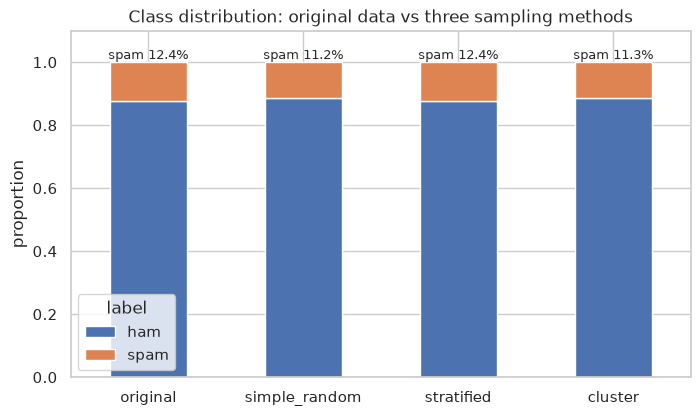

In [19]:
ax = sampling_cmp[["ham", "spam"]].plot(kind="bar", stacked=True, figsize=(8, 4.5), color=["#4C72B0", "#DD8452"])
for i, v in enumerate(sampling_cmp["spam"]):
    ax.text(i, 1.01, f"spam {v:.1%}", ha="center", fontsize=9)
ax.set_ylim(0, 1.1)
ax.set_ylabel("proportion")
ax.set_title("Class distribution: original data vs three sampling methods")
plt.xticks(rotation=0)
save_fig("sampling_comparison.png")
plt.show()

In [20]:
# One sample can be lucky or unlucky, so repeat each method 300 times with different seeds
# and look at how much the spam share moves around (standard deviation).
def one_round(seed):
    r = np.random.default_rng(seed)
    s1 = df.sample(frac=FRAC, random_state=seed)
    s2 = df.groupby("label", group_keys=False, observed=True).sample(frac=FRAC, random_state=seed)
    s3 = df[df["sample_cluster"].isin(r.choice(N_CLUSTERS, size=N_CHOSEN, replace=False))]
    return [d["label_num"].mean() for d in (s1, s2, s3)]

reps = pd.DataFrame([one_round(s) for s in range(300)], columns=["simple_random", "stratified", "cluster"])
variability = pd.DataFrame({
    "mean spam share": reps.mean(),
    "std (pp)": reps.std() * 100,
    "min": reps.min(),
    "max": reps.max(),
}).round(4)
print("Original spam share:", round(df["label_num"].mean(), 4))
variability

Original spam share: 0.1244


,mean spam share,std (pp),min,max
simple_random,0.1246,0.9163,0.0969,0.1492
stratified,0.1240,0.0000,0.1240,0.1240
cluster,0.1234,0.9239,0.1008,0.1530


**Comparison of the three methods** (original spam share = 12.44%)

| Method | One sample (seed 42) | 300 repeats: std of spam share |
|---|---|---|
| Simple random | 11.24% (-1.20 pp) | 0.92 pp |
| Stratified | 12.40% (-0.04 pp) | 0.00 pp |
| Cluster (10 of 50 blocks) | 11.26% (-1.18 pp) | 0.92 pp |

* **Stratified** sampling keeps the class proportion *exactly* every time (std = 0), because it samples
  each class separately. It is the best choice for an imbalanced label like ours (only ~12% spam), and it is
  the same idea we use later with `stratify=` in the train/test split.
* **Simple random** sampling is unbiased on average (mean 12.46% over 300 repeats) but any single sample can
  drift; with seed 42 it under-represents spam by 1.2 percentage points, and over the repeats it ranged from
  9.7% to 14.9%.
* **Cluster** sampling picks whole blocks of rows. Here it behaves similarly to simple random sampling
  (std 0.92 pp), because the file order is almost random with respect to the label - spam is spread
  evenly across the blocks. If clusters were *homogeneous* (for example all messages from one phone, or one
  spam campaign per block) cluster sampling would have a much larger error, because the effective sample size
  is the number of clusters (10), not the number of messages. Its advantage is lower collection cost,
  not accuracy.


## 7. Correlation of numerical text features
We use the numerical text features created in Section 5 plus the encoded label (`label_num`).

saved -> output/figures/correlation_heatmap.png


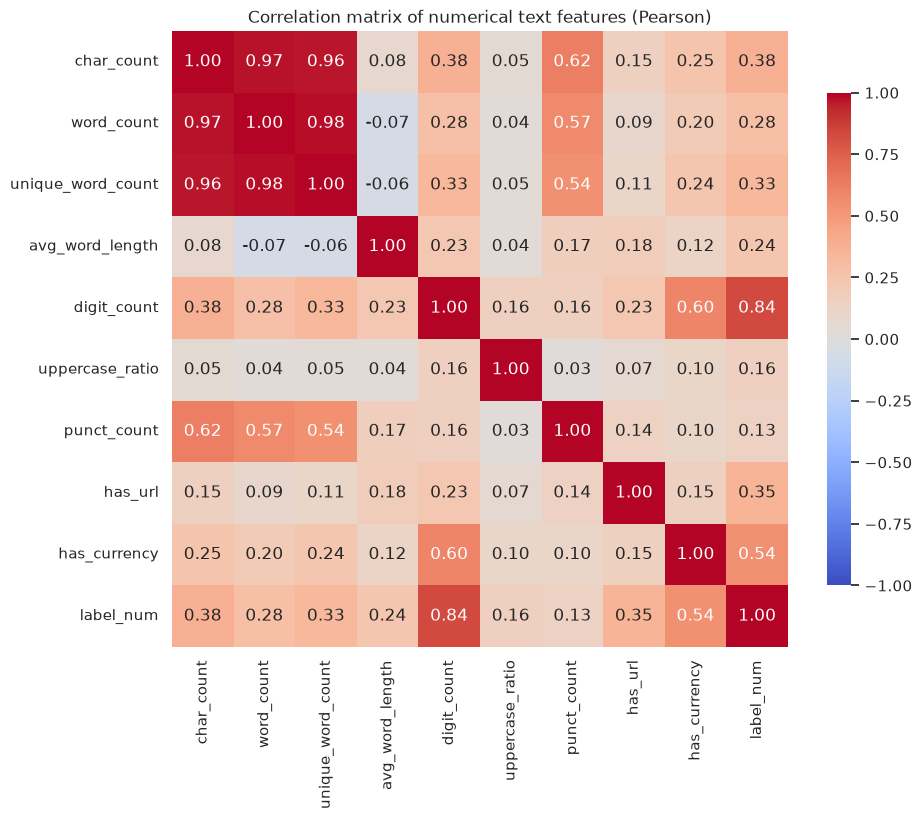

In [21]:
num_cols = ["char_count", "word_count", "unique_word_count", "avg_word_length",
            "digit_count", "uppercase_ratio", "punct_count", "has_url", "has_currency", "label_num"]
corr = df[num_cols].corr(method="pearson")

plt.figure(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, square=True, cbar_kws={"shrink": .8})
plt.title("Correlation matrix of numerical text features (Pearson)")
save_fig("correlation_heatmap.png")
plt.show()

In [22]:
# Strongest and weakest pairs (upper triangle only)
pairs = (corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
             .stack().rename("r").reset_index()
             .rename(columns={"level_0": "feature_1", "level_1": "feature_2"}))
pairs["abs_r"] = pairs["r"].abs()
print("Strongest relationships:")
display(pairs.sort_values("abs_r", ascending=False).head(6).round(3))
print("Weakest relationships:")
display(pairs.sort_values("abs_r").head(6).round(3))
print("Correlation of each feature with the spam label:")
corr["label_num"].drop("label_num").sort_values(ascending=False).round(3)

Strongest relationships:


,feature_1,feature_2,r,abs_r
12,word_count,unique_word_count,0.981,0.981
1,char_count,word_count,0.974,0.974
2,char_count,unique_word_count,0.964,0.964
49,digit_count,label_num,0.835,0.835
6,char_count,punct_count,0.621,0.621
48,digit_count,has_currency,0.599,0.599


Weakest relationships:


,feature_1,feature_2,r,abs_r
56,uppercase_ratio,punct_count,0.030,0.030
15,word_count,uppercase_ratio,0.036,0.036
35,avg_word_length,uppercase_ratio,0.040,0.040
25,unique_word_count,uppercase_ratio,0.047,0.047
5,char_count,uppercase_ratio,0.054,0.054
23,unique_word_count,avg_word_length,-0.060,0.060


Correlation of each feature with the spam label:


digit_count          0.835
has_currency         0.545
char_count           0.377
has_url              0.353
unique_word_count    0.334
word_count           0.281
avg_word_length      0.240
uppercase_ratio      0.157
punct_count          0.133
Name: label_num, dtype: float64

**Interpretation**

* **Very strong positive (r > 0.95):** `char_count`, `word_count` and `unique_word_count`
  (word_count-unique_word_count r = 0.98, char_count-word_count r = 0.97). Longer messages simply contain more
  words and more distinct words, so these three features carry almost the same information; using all of them
  in a linear model would cause multicollinearity.
* **Strong relationship with the label:** `digit_count` is by far the strongest single indicator of spam
  (r = 0.84), followed by `has_currency` (0.54). `digit_count` and `has_currency` are also related to each
  other (0.60): prices and phone numbers appear together in offers.
* **Moderate:** `char_count` (0.38), `has_url` (0.35) and `unique_word_count` (0.33) with the label; `punct_count`
  with length (0.62) - longer messages have more punctuation.
* **Weak (|r| < 0.1):** `uppercase_ratio` with almost everything (e.g. 0.03 with `punct_count`, 0.04 with
  `word_count`) and `avg_word_length` with the length features (-0.06 to 0.08). Average word length does not
  depend on how long a message is.

**Correlation does not imply causation.** The high correlation between `digit_count` and spam does not mean
that adding digits *makes* a message spam, or that removing them would make spam legitimate. Both are caused by
a third factor - the sender's intention to sell something, which requires a phone number, short code or
price. Pearson correlation only measures how two variables move together linearly; it cannot tell the
direction of the effect, it can be produced by hidden confounders or by chance, and it misses non-linear
relationships. A causal claim would need a controlled experiment.


## 8. Text analysis

### 8.1 Cleaning
A new column `cleaned_text` is created; the original `message` column is **not** changed.

Steps: handle missing text -> lowercase -> replace URLs with the token `url` -> replace e-mail
addresses with `email` -> replace currency symbols with `currency` -> replace numbers with `num` ->
remove punctuation -> collapse extra spaces.

Numbers and URLs are **replaced by a token instead of being deleted** because for spam detection
"there is a phone number / a price / a link" is useful information, while the exact number is not.

In [23]:
URL_RE = re.compile(r"(https?://\S+|www\.\S+|\b\S+\.(?:com|net|org|co\.uk|biz)\S*)")
EMAIL_RE = re.compile(r"\b[\w.+-]+@[\w-]+\.[\w.]+\b")
CURRENCY_RE = re.compile(r"[£$€]")
NUM_RE = re.compile(r"\d+(?:[.,]\d+)*")
NON_ALNUM_RE = re.compile(r"[^a-z\s]")
SPACE_RE = re.compile(r"\s+")

def clean_text(text):
    if pd.isna(text):
        return ""
    t = str(text).lower()
    t = EMAIL_RE.sub(" email ", t)
    t = URL_RE.sub(" url ", t)
    t = CURRENCY_RE.sub(" currency ", t)
    t = NUM_RE.sub(" num ", t)
    t = t.replace("'", "")            # don't -> dont, i'll -> ill
    t = NON_ALNUM_RE.sub(" ", t)      # remaining punctuation / symbols
    t = SPACE_RE.sub(" ", t).strip()
    return t

df["cleaned_text"] = df["message"].apply(clean_text)
print(clean_text(np.nan) == "", "<- missing text becomes an empty string")
df.loc[[2, 8, 15, 30], ["message", "cleaned_text"]]

True <- missing text becomes an empty string


,message,cleaned_text
2,Free entry in 2 a wkly comp to win FA Cup final tkts 21st May 2005. Text FA to 87121 to receive entry question(std t...,free entry in num a wkly comp to win fa cup final tkts num st may num text fa to num to receive entry question std t...
8,WINNER!! As a valued network customer you have been selected to receivea £900 prize reward! To claim call 0906170146...,winner as a valued network customer you have been selected to receivea currency num prize reward to claim call num c...
15,"XXXMobileMovieClub: To use your credit, click the WAP link in the next txt message or click here>> http://wap. xxxmo...",xxxmobilemovieclub to use your credit click the wap link in the next txt message or click here url url
30,"Wait that's still not all that clear, were you not sure about me being sarcastic or that that's why x doesn't want t...",wait thats still not all that clear were you not sure about me being sarcastic or that thats why x doesnt want to li...


### 8.2 Tokenization

In [24]:
df["tokens"] = df["cleaned_text"].str.split()
all_tokens = [tok for toks in df["tokens"] for tok in toks]

total_tokens = len(all_tokens)
unique_words = len(set(all_tokens))
avg_words = df["tokens"].str.len().mean()
print(f"Total tokens            : {total_tokens:,}")
print(f"Unique words (vocabulary): {unique_words:,}")
print(f"Average words per record : {avg_words:.2f}")
print(f"Empty records after cleaning: {(df['tokens'].str.len() == 0).sum()}")

Total tokens            : 82,100
Unique words (vocabulary): 7,775
Average words per record : 15.91
Empty records after cleaning: 2


### 8.3 Most frequent words (before and after stop-word removal)

In [25]:
# "call" is in scikit-learn's list, but it is one of the strongest spam words, so we keep it
STOP_WORDS = (set(ENGLISH_STOP_WORDS) - {"call"}) | {
    # SMS shorthand that behaves like stop words
    "u", "ur", "im", "ill", "dont", "r", "n", "d", "s", "m", "lt", "gt", "ok", "da", "dat",
    "wat", "oh", "hey", "lor", "la", "ya", "yeah", "just", "got", "like", "know", "come",
}

freq_all = Counter(all_tokens)
freq_nostop = Counter(t for t in all_tokens if t not in STOP_WORDS)

top20_all = pd.DataFrame(freq_all.most_common(20), columns=["word", "count"])
top20_nostop = pd.DataFrame(freq_nostop.most_common(20), columns=["word", "count"])
top20_table = pd.concat({"with stop words": top20_all, "without stop words": top20_nostop}, axis=1)
top20_table.index = range(1, 21)
share = sum(c for w, c in freq_all.most_common(20) if w in STOP_WORDS) / sum(c for _, c in freq_all.most_common(20))
print(f"Share of the top-20 counts that are stop words: {share:.1%}")
top20_table

Share of the top-20 counts that are stop words: 80.9%


with stop words       without stop words      
              word count               word count
1              num  3730                num  3730
2                i  2266               call   507
3               to  2065           currency   291
4              you  2050               free   248
5                a  1316               good   229
6              the  1247               time   211
7                u  1070                day   209
8              and   930               love   195
9               in   835               want   191
10              is   794               text   176
11              me   758               send   170
12              my   691              going   167
13             for   663               need   165
14            your   617                  p   162
15              it   597               home   158
16              of   560               stop   150
17            have   539                txt   148
18            that   510                  k   147
19            call   507              today   139
20              on   493                url   137

saved -> output/figures/word_frequency_top20.png


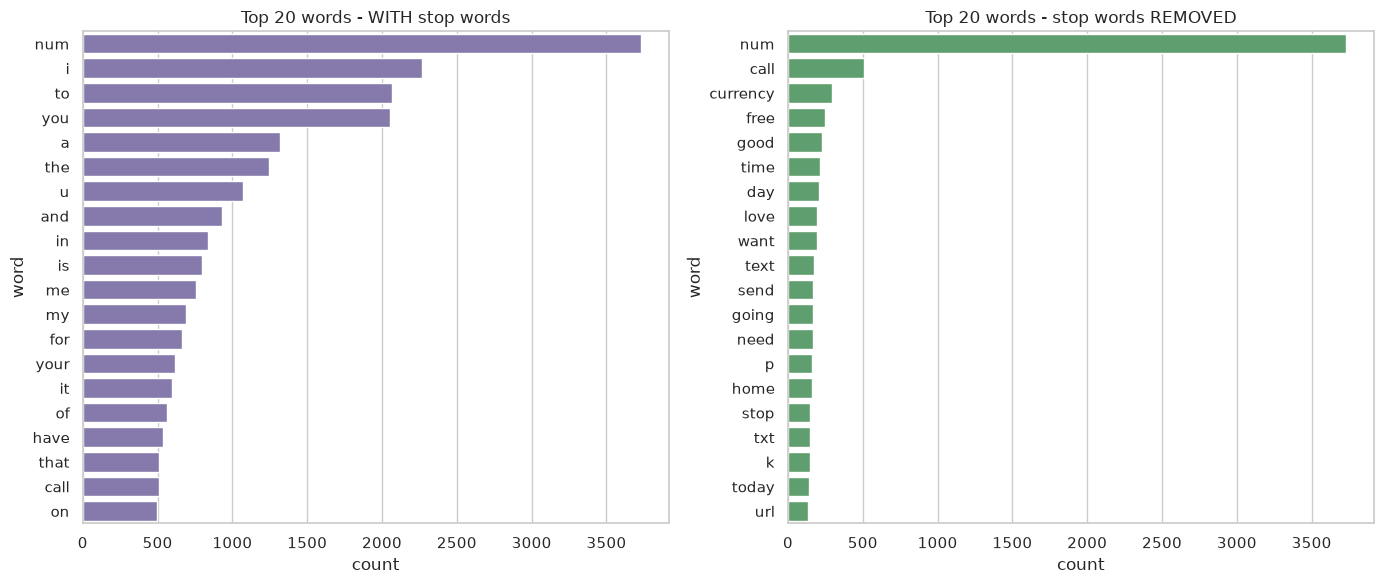

In [26]:
fig, axes = plt.subplots(1, 2, figsize=(14, 6))
sns.barplot(data=top20_all, y="word", x="count", ax=axes[0], color="#8172B3")
axes[0].set_title("Top 20 words - WITH stop words")
sns.barplot(data=top20_nostop, y="word", x="count", ax=axes[1], color="#55A868")
axes[1].set_title("Top 20 words - stop words REMOVED")
plt.tight_layout()
save_fig("word_frequency_top20.png")
plt.show()

**Result:** stop words dominate the raw list - 80.9% of the top-20 counts are stop words (`i`, `to`, `you`,
`a`, `the`, `u`...), which carry almost no meaning. After removing them the list shows the real content:
`num` (numbers, 3,730), `call` (507), `currency` (291), `free` (248), `text`, `txt`, `stop`, `url` - typical spam
vocabulary - mixed with everyday chat words such as `good`, `time`, `day`, `love`, `want`, `going`, `home`.
(`call` is in scikit-learn's stop-word list, but we kept it on purpose because it is one of the strongest spam words.)


### 8.4 Group comparison: spam vs ham

In [27]:
df["content_tokens"] = df["tokens"].apply(lambda toks: [t for t in toks if t not in STOP_WORDS])

group_stats = df.groupby("label", observed=True).agg(
    n_messages=("message", "size"),
    avg_char_length=("char_count", "mean"),
    avg_word_count=("word_count", "mean"),
    avg_unique_words=("unique_word_count", "mean"),
    avg_digits=("digit_count", "mean"),
    pct_with_url=("has_url", "mean"),
).round(2)
group_stats

,n_messages,avg_char_length,avg_word_count,avg_unique_words,avg_digits,pct_with_url
label,,,,,,
ham,4518,70.86,14.23,13.10,0.30,0.00
spam,642,137.41,23.70,22.27,15.44,0.16


In [28]:
def top_words(label, n=10):
    c = Counter(t for toks in df.loc[df["label"] == label, "content_tokens"] for t in toks)
    return pd.DataFrame(c.most_common(n), columns=["word", "count"])

top_ham, top_spam = top_words("ham"), top_words("spam")
top10 = pd.concat({"ham": top_ham, "spam": top_spam}, axis=1)
top10.index = range(1, 11)
top10

ham            spam      
     word count      word count
1     num  1102       num  2628
2    good   217      call   315
3    time   193  currency   267
4    call   192      free   192
5     day   186         p   154
6    love   185       txt   134
7   going   164       url   121
8    want   162      stop   116
9    home   156      text   108
10   need   155    mobile   107

saved -> output/figures/group_comparison_spam_vs_ham.png


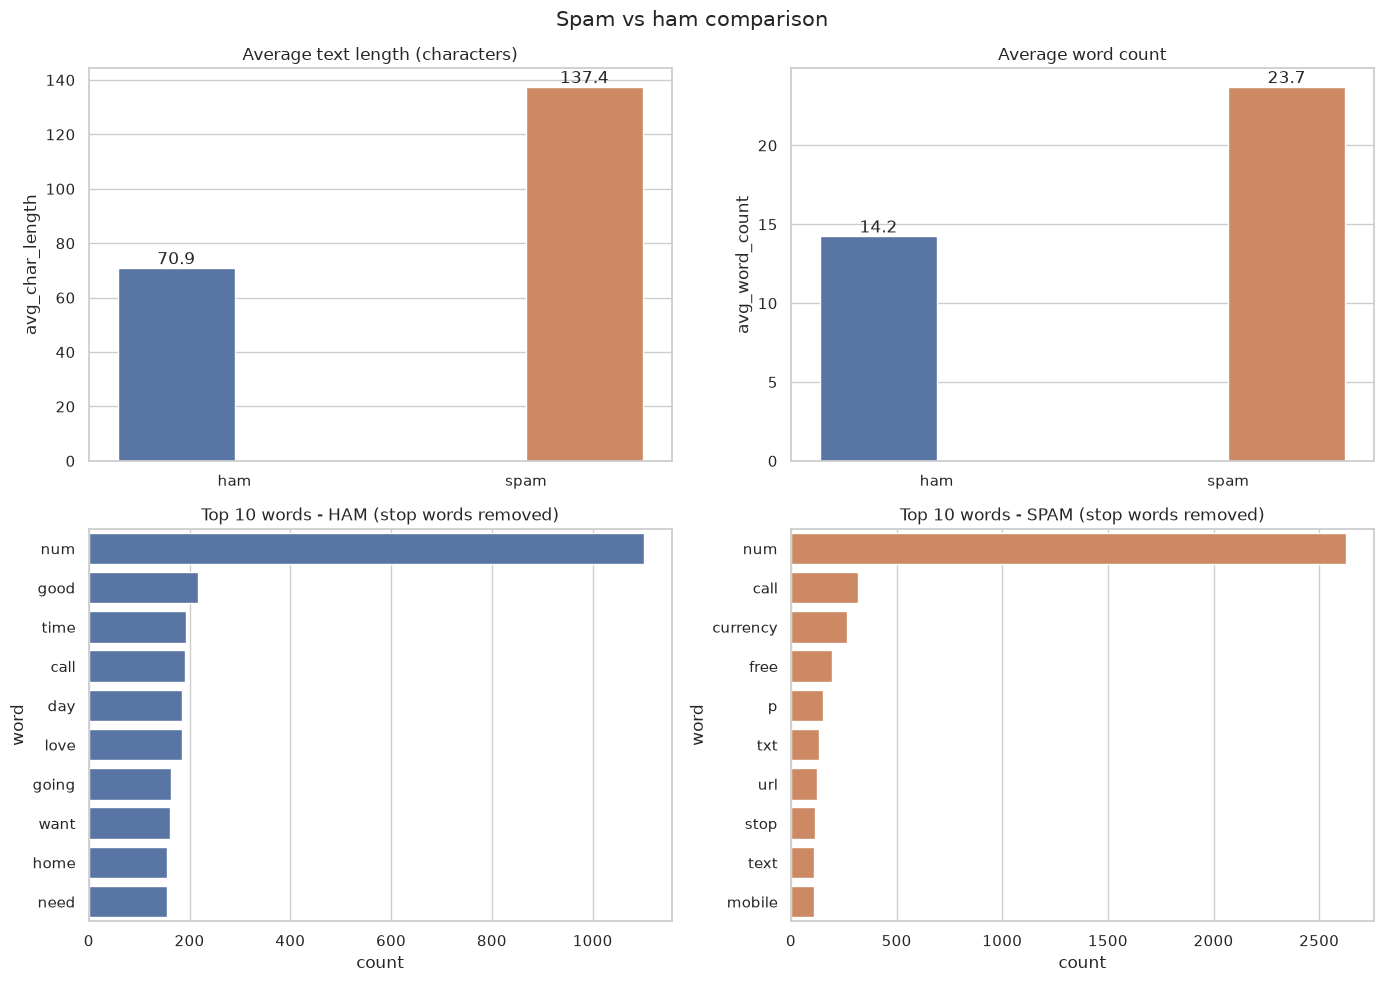

In [29]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))
palette = {"ham": "#4C72B0", "spam": "#DD8452"}

sns.barplot(x=group_stats.index, y=group_stats["avg_char_length"], hue=group_stats.index, palette=palette, legend=False, ax=axes[0, 0])
axes[0, 0].set_title("Average text length (characters)")
sns.barplot(x=group_stats.index, y=group_stats["avg_word_count"], hue=group_stats.index, palette=palette, legend=False, ax=axes[0, 1])
axes[0, 1].set_title("Average word count")
for ax in axes[0]:
    ax.set_xlabel("")
    for p in ax.patches:
        ax.annotate(f"{p.get_height():.1f}", (p.get_x() + p.get_width() / 2, p.get_height()), ha="center", va="bottom")

sns.barplot(data=top_ham, y="word", x="count", color=palette["ham"], ax=axes[1, 0])
axes[1, 0].set_title("Top 10 words - HAM (stop words removed)")
sns.barplot(data=top_spam, y="word", x="count", color=palette["spam"], ax=axes[1, 1])
axes[1, 1].set_title("Top 10 words - SPAM (stop words removed)")
plt.suptitle("Spam vs ham comparison", fontsize=15)
plt.tight_layout()
save_fig("group_comparison_spam_vs_ham.png")
plt.show()

saved -> output/figures/length_distribution_by_class.png


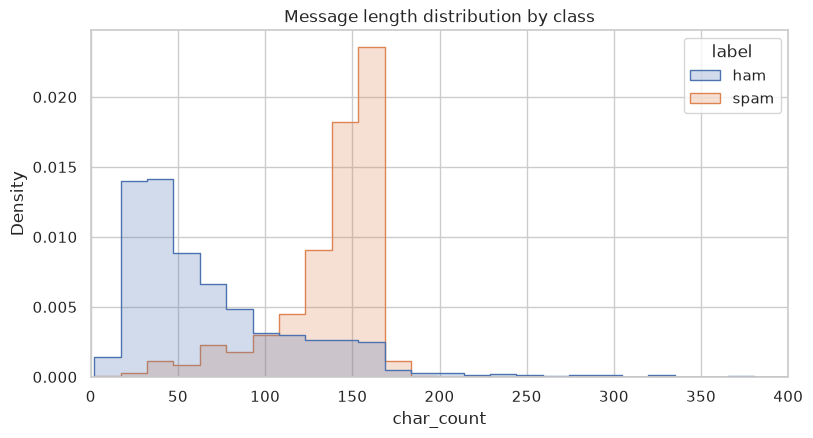

In [30]:
# Length distribution by class
plt.figure(figsize=(9, 4.5))
sns.histplot(data=df, x="char_count", hue="label", bins=60, stat="density", common_norm=False, palette=palette, element="step")
plt.xlim(0, 400)
plt.title("Message length distribution by class")
save_fig("length_distribution_by_class.png")
plt.show()

saved -> output/figures/wordclouds_ham_spam.png


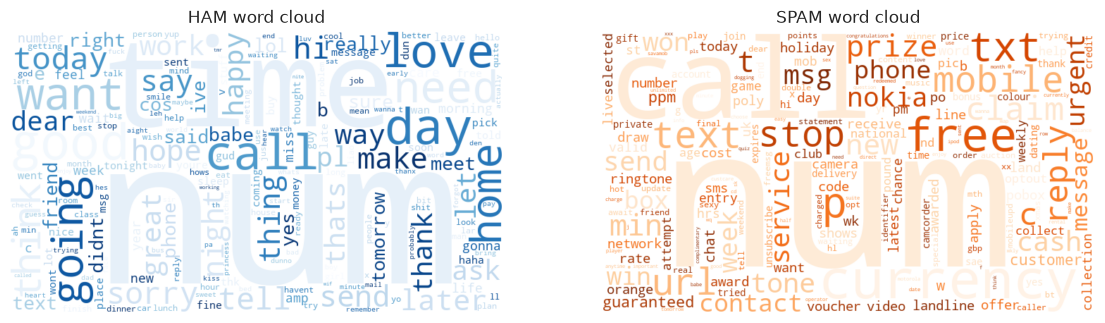

In [31]:
# Word clouds (uses the extra package installed from requirements.txt)
from wordcloud import WordCloud
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
for ax, lab, cmap in zip(axes, ["ham", "spam"], ["Blues", "Oranges"]):
    text = " ".join(" ".join(t) for t in df.loc[df["label"] == lab, "content_tokens"])
    wc = WordCloud(width=700, height=400, background_color="white", colormap=cmap,
                   random_state=RANDOM_STATE, collocations=False).generate(text)
    ax.imshow(wc, interpolation="bilinear")
    ax.set_title(f"{lab.upper()} word cloud")
    ax.axis("off")
save_fig("wordclouds_ham_spam.png")
plt.show()

In [32]:
# Evidence used in the written insights below
spam_rate_by_bin = pd.crosstab(df["length_bin"], df["label"], normalize="index")["spam"]
evidence = {
    "spam avg chars": group_stats.loc["spam", "avg_char_length"],
    "ham avg chars": group_stats.loc["ham", "avg_char_length"],
    "spam avg words": group_stats.loc["spam", "avg_word_count"],
    "ham avg words": group_stats.loc["ham", "avg_word_count"],
    "spam avg digits": group_stats.loc["spam", "avg_digits"],
    "ham avg digits": group_stats.loc["ham", "avg_digits"],
    "% spam with 'num' token": (df[df.label == "spam"]["tokens"].apply(lambda t: "num" in t).mean() * 100).round(1),
    "% ham with 'num' token": (df[df.label == "ham"]["tokens"].apply(lambda t: "num" in t).mean() * 100).round(1),
    "% spam with 'free'": (df[df.label == "spam"]["tokens"].apply(lambda t: "free" in t).mean() * 100).round(1),
    "% ham with 'free'": (df[df.label == "ham"]["tokens"].apply(lambda t: "free" in t).mean() * 100).round(1),
    "spam share of long (>160) msgs": round(spam_rate_by_bin.iloc[-1] * 100, 1),
    "spam share of very short (<=40) msgs": round(spam_rate_by_bin.iloc[0] * 100, 1),
    "% spam with url": round(group_stats.loc["spam", "pct_with_url"] * 100, 1),
    "% ham with url": round(group_stats.loc["ham", "pct_with_url"] * 100, 1),
    "corr(digit_count, label)": round(corr.loc["digit_count", "label_num"], 3),
    "spam avg uppercase ratio": round(df[df.label == "spam"]["uppercase_ratio"].mean(), 3),
    "ham avg uppercase ratio": round(df[df.label == "ham"]["uppercase_ratio"].mean(), 3),
}
pd.Series(evidence, name="value").to_frame()

,value
spam avg chars,137.410
ham avg chars,70.860
spam avg words,23.700
ham avg words,14.230
spam avg digits,15.440
ham avg digits,0.300
% spam with 'num' token,93.300
% ham with 'num' token,15.900
% spam with 'free',22.700
% ham with 'free',1.200


### 8.5 Written insights

**Insight 1 - Spam messages are about twice as long as ham.**
* *Observation:* spam is much longer than normal messages.
* *Evidence:* average length 137.4 vs 70.9 characters and 23.7 vs 14.2 words. Only 0.6% of very short messages
  (<= 40 chars) are spam, but 31.6% of medium messages (81-160 chars) are spam. Above 160 characters the share drops
  to 20.7%.
* *Interpretation:* a spam SMS has to fit an offer, instructions, a number and T&Cs into one message, so it uses
  almost the full 160-character SMS limit - but rarely more, because a second SMS costs the sender money. Very short
  messages ("Ok...", "U too") are almost always personal.

**Insight 2 - Numbers are the single strongest spam signal.**
* *Observation:* spam is full of digits; ham rarely has any.
* *Evidence:* 93.3% of spam messages contain at least one number (`num` token) vs 15.9% of ham; average digits per
  message 15.44 vs 0.30; correlation between `digit_count` and the label r = 0.835 (the highest in the heatmap).
* *Interpretation:* spam always asks for an action - call a premium number, text a short code, pay a price -
  so it needs numbers. This is also why we replaced numbers with a `num` token instead of deleting them.

**Insight 3 - Spam uses a small, repetitive, commercial vocabulary.**
* *Observation:* the spam top-10 is very different from the ham top-10.
* *Evidence:* spam top words: `num, call, currency, free, p (pence, as in 150p), txt, url, stop, text, mobile`.
  `free` appears in 22.7% of spam but only 1.2% of ham. The Naive Bayes model's most spam-indicative terms are
  `claim, prize, won, nokia, guaranteed, ppm, ringtone, awarded`. 94 of the 747 original spam rows (12.6%) were exact
  duplicates, compared with 6.4% for ham.
* *Interpretation:* spam is produced from templates and sent in campaigns, so the same words and even the same
  messages repeat. This makes spam easy to detect with bag-of-words models such as TF-IDF.

**Insight 4 - Ham is informal, conversational and partly regional (Singapore/UK slang).**
* *Observation:* legitimate messages are personal chat written in SMS shorthand.
* *Evidence:* ham top words: `good, time, call, day, love, going, want, home, need`. The most ham-indicative terms
  of the classifier are `later, thats, doing, lol, really, didnt, gonna, cos`, and K-Means found a cluster with
  words such as `dun, wan, thk, lor, lunch, dinner` (Singlish) that contains **no** spam at all.
* *Interpretation:* cleaning must handle non-standard spelling; we had to add SMS shorthand (`u, ur, lor, da, im`)
  to the stop-word list. A model trained on this data may not transfer well to formal English or other regions.

**Insight 5 - Links and money mentions are almost exclusive to spam.**
* *Observation:* URLs and currency appear nearly only in spam.
* *Evidence:* 16.0% of spam contains a URL / web address vs about 0% of ham; `has_currency` has r = 0.545 with
  the label, and `currency` is the 3rd most frequent spam word (267 times).
* *Interpretation:* sending the receiver to a website or mentioning a cash prize is a strong red flag. These
  simple binary features could be combined with TF-IDF in a production filter.

**Insight 6 - Capital letters help a little, but much less than expected.**
* *Observation:* spam "shouts" more (FREE, URGENT, WINNER).
* *Evidence:* average uppercase ratio 0.110 for spam vs 0.057 for ham, but the correlation with the label is only
  r = 0.157.
* *Interpretation:* many ham messages are also written fully in capitals ("I HAVE A DATE ON SUNDAY WITH WILL!!"),
  so uppercase is a weak signal on its own - which is also why we lowercase the text before modelling.


## 9. Supervised text classification (TF-IDF + Multinomial Naive Bayes)

* **Target:** `label_num` (spam = 1, ham = 0). Spam is the *positive* class, so precision, recall
  and F1 are reported for spam.
* **Split:** 80% train / 20% test, **stratified** by label because the classes are imbalanced.
* **Features:** TF-IDF on `cleaned_text`. The vectorizer is fitted **only on the training set** to
  avoid information leaking from the test set.
* **Model:** Multinomial Naive Bayes - a fast, standard baseline for word-count/TF-IDF features.

In [33]:
X = df["cleaned_text"]
y = df["label_num"]
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, stratify=y, random_state=RANDOM_STATE)

print("train:", X_train.shape[0], "| test:", X_test.shape[0])
print("spam share - train: %.4f | test: %.4f" % (y_train.mean(), y_test.mean()))

tfidf = TfidfVectorizer(stop_words=list(STOP_WORDS), min_df=2, sublinear_tf=True)
Xtr = tfidf.fit_transform(X_train)
Xte = tfidf.transform(X_test)
print("TF-IDF matrix (train):", Xtr.shape)

nb = MultinomialNB(alpha=0.1)
nb.fit(Xtr, y_train)
y_pred = nb.predict(Xte)

def metrics(y_true, y_hat):
    return {"accuracy": accuracy_score(y_true, y_hat),
            "precision_spam": precision_score(y_true, y_hat),
            "recall_spam": recall_score(y_true, y_hat),
            "f1_spam": f1_score(y_true, y_hat),
            "f1_macro": f1_score(y_true, y_hat, average="macro")}

nb_metrics = metrics(y_test, y_pred)
nb_report = classification_report(y_test, y_pred, target_names=["ham", "spam"], digits=4)
nb_cm = confusion_matrix(y_test, y_pred)
print(pd.Series(nb_metrics).round(4))
print()
print(nb_report)

train: 4128 | test: 1032
spam share - train: 0.1245 | test: 0.1240
TF-IDF matrix (train): (4128, 2800)
accuracy          0.9738
precision_spam    0.9040
recall_spam       0.8828
f1_spam           0.8933
f1_macro          0.9392
dtype: float64

              precision    recall  f1-score   support

         ham     0.9835    0.9867    0.9851       904
        spam     0.9040    0.8828    0.8933       128

    accuracy                         0.9738      1032
   macro avg     0.9437    0.9348    0.9392      1032
weighted avg     0.9736    0.9738    0.9737      1032



saved -> output/figures/confusion_matrix_nb.png


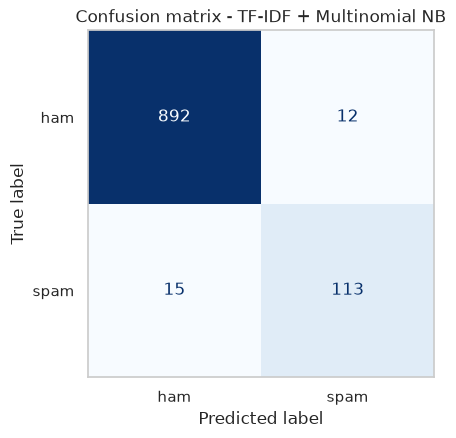

TN=892  FP=12 (ham flagged as spam)  FN=15 (spam missed)  TP=113


In [34]:
fig, ax = plt.subplots(figsize=(5.5, 4.5))
ConfusionMatrixDisplay(nb_cm, display_labels=["ham", "spam"]).plot(ax=ax, cmap="Blues", values_format="d", colorbar=False)
ax.set_title("Confusion matrix - TF-IDF + Multinomial NB")
ax.grid(False)
save_fig("confusion_matrix_nb.png")
plt.show()

tn, fp, fn, tp = nb_cm.ravel()
print(f"TN={tn}  FP={fp} (ham flagged as spam)  FN={fn} (spam missed)  TP={tp}")

In [35]:
# Words with the highest spam log-probability ratio learned by the model
feat = np.array(tfidf.get_feature_names_out())
log_ratio = nb.feature_log_prob_[1] - nb.feature_log_prob_[0]
print("Most spam-indicative terms:", ", ".join(feat[np.argsort(log_ratio)[-15:][::-1]]))
print("Most ham-indicative terms :", ", ".join(feat[np.argsort(log_ratio)[:15]]))

# A few misclassified test messages
test_df = pd.DataFrame({"message": df.loc[X_test.index, "message"], "true": y_test, "pred": y_pred})
test_df[test_df["true"] != test_df["pred"]].head(8)

Most spam-indicative terms: claim, prize, won, nokia, cs, guaranteed, ppm, tone, ringtone, pobox, tones, awarded, landline, weekly, collection
Most ham-indicative terms : later, thats, doing, lol, ask, really, didnt, sure, said, coming, let, thing, morning, gonna, cos


,message,true,pred
4431,Cashbin.co.uk (Get lots of cash this weekend!) www.cashbin.co.uk Dear Welcome to the weekend We have got our biggest...,1,0
4410,I (Career Tel) have added u as a contact on INDYAROCKS.COM to send FREE SMS. To remove from phonebook - sms NO to &...,0,1
1224,"Hungry gay guys feeling hungry and up 4 it, now. Call 08718730555 just 10p/min. To stop texts call 08712460324 (10p/...",1,0
3515,"It‘s £6 to get in, is that ok?",0,1
2948,Good Luck! Draw takes place 28th Feb 06. Good Luck! For removal send STOP to 87239 customer services 08708034412,1,0
3173,Sorry I missed your call let's talk when you have the time. I'm on 07090201529,1,0
4531,Nokia phone is lovly..,0,1
486,Are you free now?can i call now?,0,1


**Interpretation**

* **Accuracy = 97.4%**, but accuracy alone is misleading on an imbalanced dataset: a model that always predicts
  "ham" would already get 87.6% on this test set (904 of 1032). That is why we report precision, recall and F1
  for the spam class.
* **Spam precision = 0.904:** when the model says "spam" it is right 90% of the time - 12 legitimate messages
  were wrongly flagged (false positives). Looking at them, they contain spam-like words in a personal context,
  e.g. *"Are you free now? can i call now?"*, *"Nokia phone is lovly.."*, *"It's £6 to get in, is that ok?"*.
* **Spam recall = 0.883:** 113 of 128 spam messages were caught and 15 were missed (false negatives). Missed spam is
  usually spam that looks unusual - a web address instead of a phone number (*"Cashbin.co.uk ..."*) or a polite,
  conversational style (*"Sorry I missed your call let's talk ... I'm on 07090..."*).
* **F1 (spam) = 0.893, macro F1 = 0.939.** The words the model relies on most for spam (`claim, prize, won,
  guaranteed, ringtone, ppm`) match the text analysis in Section 8, so the model learned meaningful patterns.

**Limitations**

1. **Class imbalance / small test set:** there are only 128 spam messages in the test set, so one extra error
   changes recall by about 0.8 percentage points. Cross-validation (Section 10) gives a more stable estimate.
2. **Bag of words:** TF-IDF ignores word order and context ("are you free now" vs "FREE entry"), which explains
   most of the false positives, and it cannot use words that were never seen in training.
3. **Old, regional data:** the messages were collected around 2011 from UK and Singapore sources. Modern spam
   (phishing links, delivery scams, crypto) looks different, so the model would need new training data.
4. Naive Bayes assumes that words are independent given the class, which is not true in real text.


In [36]:
# Collect the main-model results for output/model_metrics.txt (the file is written in Section 12)
metrics_lines = [
    "CSCI461 Assignment 1 - Supervised text classification results",
    "Dataset: SMS Spam Collection (UCI #228), after removing duplicates: %d messages" % len(df),
    "Target: label (spam = 1 = positive class, ham = 0)",
    "Split: 80%% train / 20%% test, stratified, random_state=%d  (train=%d, test=%d)" % (RANDOM_STATE, len(X_train), len(X_test)),
    "Features: TF-IDF on cleaned_text (stop words removed, min_df=2, sublinear_tf)",
    "",
    "=== Main model: Multinomial Naive Bayes (alpha=0.1) ===",
]
metrics_lines += [f"{k:15s}: {v:.4f}" for k, v in nb_metrics.items()]
metrics_lines += ["", "Classification report:", nb_report,
    "Confusion matrix (rows = true, cols = predicted, order = [ham, spam]):",
    str(nb_cm),
    f"TN={tn}  FP={fp}  FN={fn}  TP={tp}",
    "",
    f"Interpretation: accuracy {nb_metrics['accuracy']:.1%} vs {1 - y_test.mean():.1%} for always predicting ham, so accuracy alone",
    f"is misleading. Spam precision {nb_metrics['precision_spam']:.3f} ({fp} ham messages flagged as spam) and spam recall",
    f"{nb_metrics['recall_spam']:.3f} ({fn} spam messages missed). False positives are personal messages that use spam-like",
    "words (free, call, nokia, prices); missed spam uses a web address instead of a number or a conversational style.",
    "Limitations: class imbalance (small number of spam in the test set), bag-of-words ignores word order and",
    "context, data is old (2011) and regional so modern spam may differ, NB assumes word independence."]
print(f"{len(metrics_lines)} lines ready for model_metrics.txt")

25 lines ready for model_metrics.txt


## 10. Bonus - model extension

*To be added: comparison of classifiers + n-grams + hyperparameter tuning.*

## 11. K-Means clustering (unsupervised)

K-Means is **unsupervised**: it never sees the `label` column. It groups messages only by how
similar their TF-IDF vectors are.

**Representation:** TF-IDF (unigrams, stop words removed, `min_df=3`) -> **TruncatedSVD** to 50
dimensions (LSA: keeps the main topics, removes noise and makes K-Means faster) -> **L2 normalisation**
so Euclidean distance behaves like cosine similarity, which suits text.

**Choosing k:** we do *not* fix k in advance. First we run an experiment for k = 2 ... 12 and compare
the **silhouette score** (higher = better separated clusters) and the **inertia** (elbow method).

In [37]:
km_tfidf = TfidfVectorizer(stop_words=list(STOP_WORDS), min_df=3, sublinear_tf=True)
X_km_tfidf = km_tfidf.fit_transform(df["cleaned_text"])
svd = TruncatedSVD(n_components=50, random_state=RANDOM_STATE)
X_km = Normalizer(copy=False).fit_transform(svd.fit_transform(X_km_tfidf))
print("TF-IDF:", X_km_tfidf.shape, "-> SVD:", X_km.shape,
      f"| explained variance kept: {svd.explained_variance_ratio_.sum():.1%}")

k_range = range(2, 13)
k_results, k_models = [], {}
for k in k_range:
    km = KMeans(n_clusters=k, n_init=20, random_state=RANDOM_STATE)
    lab = km.fit_predict(X_km)
    k_models[k] = km
    k_results.append({"k": k, "inertia": km.inertia_, "silhouette": silhouette_score(X_km, lab)})
k_df = pd.DataFrame(k_results).set_index("k")
k_df.round(4)

TF-IDF: (5160, 2178) -> SVD: (5160, 50) | explained variance kept: 18.3%


,inertia,silhouette
k,,
2,4334.7897,0.0626
3,4221.4560,0.0636
4,4136.5022,0.0687
5,4052.6306,0.0706
6,3969.3032,0.0773
7,3906.3798,0.0819
8,3840.0399,0.0900
9,3791.3872,0.0888
10,3726.5181,0.0973


saved -> output/figures/kmeans_k_selection.png


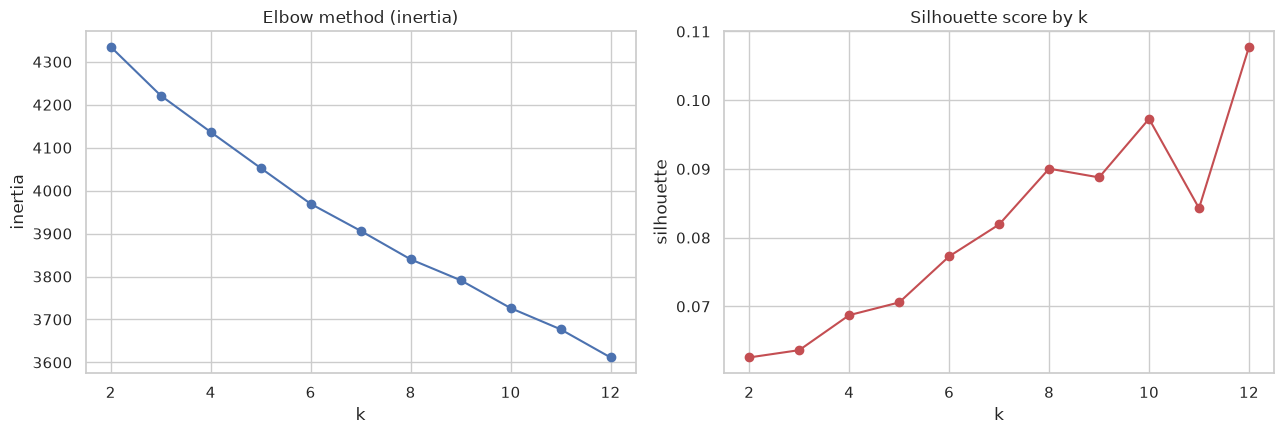

In [38]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
axes[0].plot(k_df.index, k_df["inertia"], "o-")
axes[0].set_title("Elbow method (inertia)")
axes[0].set_xlabel("k")
axes[0].set_ylabel("inertia")
axes[1].plot(k_df.index, k_df["silhouette"], "o-", color="#C44E52")
axes[1].set_title("Silhouette score by k")
axes[1].set_xlabel("k")
axes[1].set_ylabel("silhouette")
plt.tight_layout()
save_fig("kmeans_k_selection.png")
plt.show()

**Choosing k - result of the experiment**

* The silhouette score is **low for every k (0.063 to 0.108)** and it rises slowly as k grows (highest at k = 12, the
  edge of the range). The inertia curve decreases smoothly without a clear elbow.
* This is typical for short text: TF-IDF vectors are sparse and topics overlap, so there are no well-separated
  "natural" groups. Silhouette keeps improving with more clusters simply because each cluster becomes smaller and
  tighter, so "take the maximum" would push us to an ever-larger k with tiny, hard-to-interpret clusters.
* We therefore choose **k = 2 from the structure of the data**: the corpus is produced by two kinds of senders -
  businesses sending promotional messages and people chatting. Using k = 2 lets us test whether K-Means can find
  this split **without seeing the labels**. A larger k (k = 6) is also inspected below to show the finer topics.


In [39]:
# Decision (explained in the markdown above): k = 2, from the structure of the data
BEST_K = 2
print("Highest silhouette in the experiment: k =", int(k_df["silhouette"].idxmax()),
      f"({k_df['silhouette'].max():.4f})  - range of all values: {k_df['silhouette'].min():.4f} to {k_df['silhouette'].max():.4f}")
print("Chosen k:", BEST_K)

kmeans = k_models[BEST_K]          # the same fitted model that was scored above
df["cluster"] = kmeans.labels_
sil = silhouette_score(X_km, df["cluster"])
cluster_sizes = df["cluster"].value_counts().sort_index()
print(f"Silhouette score (k={BEST_K}): {sil:.4f}")
print("\nRecords per cluster:")
print(cluster_sizes)

Highest silhouette in the experiment: k = 12 (0.1078)  - range of all values: 0.0626 to 0.1078
Chosen k: 2


Silhouette score (k=2): 0.0626

Records per cluster:
cluster
0    3994
1    1166
Name: count, dtype: int64


In [40]:
# Top terms per cluster: project the centroids back from SVD space to TF-IDF term space
centroids_terms = svd.inverse_transform(kmeans.cluster_centers_)
terms = km_tfidf.get_feature_names_out()
top_terms = {c: [terms[i] for i in centroids_terms[c].argsort()[::-1][:12]] for c in range(BEST_K)}

ct = pd.crosstab(df["cluster"], df["label"])
ct["size"] = ct.sum(axis=1)
ct["spam_share"] = (ct["spam"] / ct["size"]).round(3)
ct["top_terms"] = [", ".join(top_terms[c]) for c in ct.index]
ct

label,ham,spam,size,spam_share,top_terms
cluster,,,,,
0,3944,50,3994,0.013,"good, time, think, today, babe, really, ask, love, dear, great, night, let"
1,574,592,1166,0.508,"num, currency, call, free, txt, stop, url, reply, text, mobile, new, claim"


In [41]:
# Representative (closest-to-centroid) messages for each cluster
dist_to_centroid = kmeans.transform(X_km)
for c in range(BEST_K):
    idx = np.where(df["cluster"] == c)[0]
    closest = idx[np.argsort(dist_to_centroid[idx, c])[:3]]
    print(f"--- cluster {c} (n={len(idx)}, spam share={ct.loc[c, 'spam_share']:.1%})")
    for i in closest:
        print("   ", df.loc[i, "message"][:110])

--- cluster 0 (n=3994, spam share=1.3%)
    I have many dependents
    What about this one then.
    S:)s.nervous  &lt;#&gt; :)
--- cluster 1 (n=1166, spam share=50.8%)
    08714712388 between 10am-7pm Cost 10p
    You will recieve your tone within the next 24hrs. For Terms and conditions please see Channel U Teletext Pg 75
    I know complain num only..bettr directly go to bsnl offc nd apply for it..


In [42]:
# Extra exploration: a larger k splits the data into finer topics (mostly inside ham)
K_TOPICS = 6
km6 = k_models[K_TOPICS]
cent6 = svd.inverse_transform(km6.cluster_centers_)
topics = pd.crosstab(km6.labels_, df["label"]).rename_axis(f"cluster (k={K_TOPICS})")
topics["size"] = topics.sum(axis=1)
topics["spam_share"] = (topics["spam"] / topics["size"]).round(3)
topics["top_terms"] = [", ".join(terms[i] for i in cent6[c].argsort()[::-1][:10]) for c in topics.index]
topics

label,ham,spam,size,spam_share,top_terms
cluster (k=6),,,,,
0,176,7,183,0.038,"time, num, finish, week, soon, coming, want, long, wan, make"
1,429,578,1007,0.574,"num, currency, call, free, txt, stop, url, reply, text, mobile"
2,948,8,956,0.008,"let, ive, really, sure, sent, babe, said, make, told, late"
3,2321,46,2367,0.019,"love, want, call, home, think, going, need, great, right, dear"
4,436,0,436,0.000,"wan, meet, ask, dun, yup, num, say, thk, dinner, lunch"
5,208,3,211,0.014,"good, morning, day, night, hope, love, happy, num, sleep, dear"


saved -> output/figures/kmeans_clusters_vs_labels.png


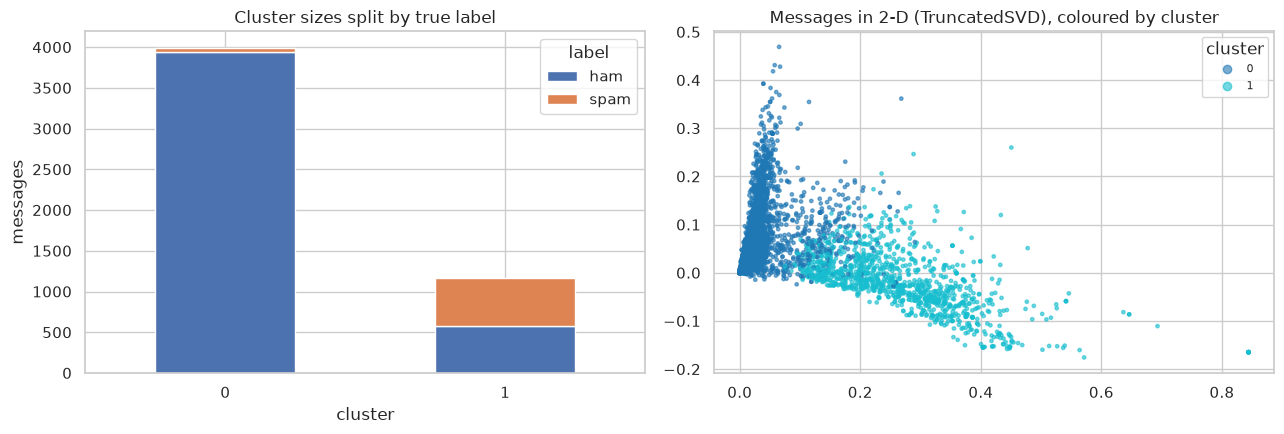

Cluster purity w.r.t. spam/ham labels: 0.879  (majority-class baseline = 0.876)
Adjusted Rand Index (clusters vs labels, 0 = random, 1 = identical): 0.488
Share of all spam that falls in cluster 1: 92.2%


In [43]:
# High-level comparison with the true labels
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
pd.crosstab(df["cluster"], df["label"]).plot(kind="bar", stacked=True, ax=axes[0], color=["#4C72B0", "#DD8452"], rot=0)
axes[0].set_title("Cluster sizes split by true label")
axes[0].set_ylabel("messages")

svd2 = TruncatedSVD(n_components=2, random_state=RANDOM_STATE).fit_transform(X_km_tfidf)
sc = axes[1].scatter(svd2[:, 0], svd2[:, 1], c=df["cluster"], cmap="tab10", s=6, alpha=.6)
axes[1].set_title("Messages in 2-D (TruncatedSVD), coloured by cluster")
axes[1].legend(*sc.legend_elements(), title="cluster", loc="upper right", fontsize=8)
plt.tight_layout()
save_fig("kmeans_clusters_vs_labels.png")
plt.show()

# purity: how well clusters line up with labels if each cluster is mapped to its majority label
purity = pd.crosstab(df["cluster"], df["label"]).max(axis=1).sum() / len(df)
ari = adjusted_rand_score(df["label_num"], df["cluster"])
spam_cluster = int(ct["spam_share"].idxmax())
spam_captured = ct.loc[spam_cluster, "spam"] / ct["spam"].sum()
print(f"Cluster purity w.r.t. spam/ham labels: {purity:.3f}  (majority-class baseline = {1 - df.label_num.mean():.3f})")
print(f"Adjusted Rand Index (clusters vs labels, 0 = random, 1 = identical): {ari:.3f}")
print(f"Share of all spam that falls in cluster {spam_cluster}: {spam_captured:.1%}")

**Cluster interpretation and comparison with labels**

* **Cluster 0 - personal conversation (3,994 messages, 1.3% spam).** Top terms `good, time, think, today, babe,
  really, love, dear, night` - everyday chat between friends and family.
* **Cluster 1 - "action / commercial" messages (1,166 messages, 50.8% spam).** Top terms `num, currency, call, free,
  txt, stop, url, reply, text, mobile, claim` - messages that contain numbers, prices, links and instructions to
  call or reply. It contains **92.2% of all spam**, but also 574 ham messages that mention numbers, times or calls
  (e.g. *"I know complain num only..bettr directly go to bsnl offc"*).
* **Quality:** silhouette = 0.063 (weak, overlapping clusters, as expected for short text). Adjusted Rand Index with the
  true labels = 0.488 (moderate agreement; 0 would be random). Purity is 0.879 - only slightly above the 0.876 you
  would get by calling everything ham, because cluster 1 is half ham.
* **Larger k (k = 6):** one spam-heavy cluster remains (57% spam) and the ham messages split into topics: arranging
  meetings/food in Singlish (`wan, meet, dun, dinner, lunch` - 0 spam), greetings (`good morning, night, hope`),
  love/home, timing (`time, finish, soon`) and general chat.
* **Comparison with labels:** cluster IDs are arbitrary numbers and do not equal class IDs. K-Means groups messages by
  *vocabulary*, not by *intent*: it rediscovers "messages full of numbers and calls to action", which overlaps strongly
  with spam but is not the same thing. That is why the supervised model (spam F1 0.89 already for the Naive Bayes baseline) is far better for detecting
  spam, while K-Means is useful for exploring the topics in the data without labels.


## 12. Save outputs

In [44]:
# 1) cleaned data (token lists are dropped - they can be rebuilt from cleaned_text)
cleaned_cols = ["label", "label_num", "message", "cleaned_text", "char_count", "word_count",
                "unique_word_count", "avg_word_length", "digit_count", "uppercase_ratio", "punct_count",
                "has_url", "has_currency", "length_bin", "char_count_minmax", "cluster"]
df[cleaned_cols].to_csv(OUT_DIR / "cleaned_data.csv", index=False, encoding="utf-8")
print("saved -> output/cleaned_data.csv", df[cleaned_cols].shape)

saved -> output/cleaned_data.csv (5160, 16)


In [45]:
# 2) model_metrics.txt (main model from Section 9 + bonus from Section 10)
(OUT_DIR / "model_metrics.txt").write_text("\n".join(metrics_lines), encoding="utf-8")
print("\n".join(metrics_lines))

CSCI461 Assignment 1 - Supervised text classification results
Dataset: SMS Spam Collection (UCI #228), after removing duplicates: 5160 messages
Target: label (spam = 1 = positive class, ham = 0)
Split: 80% train / 20% test, stratified, random_state=42  (train=4128, test=1032)
Features: TF-IDF on cleaned_text (stop words removed, min_df=2, sublinear_tf)

=== Main model: Multinomial Naive Bayes (alpha=0.1) ===
accuracy       : 0.9738
precision_spam : 0.9040
recall_spam    : 0.8828
f1_spam        : 0.8933
f1_macro       : 0.9392

Classification report:
              precision    recall  f1-score   support

         ham     0.9835    0.9867    0.9851       904
        spam     0.9040    0.8828    0.8933       128

    accuracy                         0.9738      1032
   macro avg     0.9437    0.9348    0.9392      1032
weighted avg     0.9736    0.9738    0.9737      1032

Confusion matrix (rows = true, cols = predicted, order = [ham, spam]):
[[892  12]
 [ 15 113]]
TN=892  FP=12  FN=15  T

In [46]:
CLUSTER_TEXT = "k was chosen from the data structure (commercial vs personal senders) because silhouette was low for every k (0.063-0.108) and kept rising slowly with k, without a clear peak or elbow.\nCluster 0 (3994 msgs, 1.3% spam) = personal conversation: good, time, think, today, love, night.\nCluster 1 (1166 msgs, 50.8% spam) = 'action/commercial' messages with numbers, prices, links and calls to action (num, currency, call, free, txt, stop, url, claim). It holds 92.2% of all spam but also 574 ham messages that mention numbers or calls.\nSilhouette 0.063 means the clusters overlap (normal for short, sparse text). ARI 0.488 shows moderate agreement with the true labels. K-Means groups by vocabulary, not by intent, so it does not replace the supervised classifier; cluster IDs do not correspond to class IDs."

# 3) cluster_summary.txt
lines = [
    "CSCI461 Assignment 1 - K-Means clustering summary",
    "Representation: TF-IDF (stop words removed, min_df=3) -> TruncatedSVD(50) -> L2 normalisation",
    f"k tested: 2..12 ; chosen k = {BEST_K} (silhouette has no clear peak, so k comes from the data structure: commercial vs personal messages)",
    "",
    "Silhouette score per k:",
    k_df["silhouette"].round(4).to_string(),
    "",
    f"Quality measure - silhouette score for k={BEST_K}: {sil:.4f}",
    f"Cluster purity vs true spam/ham labels: {purity:.3f} ; Adjusted Rand Index: {ari:.3f}",
    f"Share of all spam messages captured by cluster {spam_cluster}: {spam_captured:.1%}",
    "",
    "Cluster sizes and composition:",
    ct[["size", "ham", "spam", "spam_share"]].to_string(),
    "",
    "Top terms per cluster:",
]
lines += [f"  cluster {c}: {', '.join(top_terms[c])}" for c in range(BEST_K)]
lines += ["", "Interpretation:", CLUSTER_TEXT]
(OUT_DIR / "cluster_summary.txt").write_text("\n".join(lines), encoding="utf-8")
print("\n".join(lines))

CSCI461 Assignment 1 - K-Means clustering summary
Representation: TF-IDF (stop words removed, min_df=3) -> TruncatedSVD(50) -> L2 normalisation
k tested: 2..12 ; chosen k = 2 (silhouette has no clear peak, so k comes from the data structure: commercial vs personal messages)

Silhouette score per k:
k
2     0.0626
3     0.0636
4     0.0687
5     0.0706
6     0.0773
7     0.0819
8     0.0900
9     0.0888
10    0.0973
11    0.0843
12    0.1078

Quality measure - silhouette score for k=2: 0.0626
Cluster purity vs true spam/ham labels: 0.879 ; Adjusted Rand Index: 0.488
Share of all spam messages captured by cluster 1: 92.2%

Cluster sizes and composition:
label    size   ham  spam  spam_share
cluster                              
0        3994  3944    50       0.013
1        1166   574   592       0.508

Top terms per cluster:
  cluster 0: good, time, think, today, babe, really, ask, love, dear, great, night, let
  cluster 1: num, currency, call, free, txt, stop, url, reply, text, mobile,

In [47]:
print("Files in output/:")
for p in sorted(OUT_DIR.rglob("*")):
    if p.is_file():
        print(f"  {p.relative_to(OUT_DIR)}  ({p.stat().st_size:,} bytes)")

Files in output/:
  cleaned_data.csv  (1,119,750 bytes)
  cluster_summary.txt  (1,832 bytes)
  figures/confusion_matrix_nb.png  (17,768 bytes)
  figures/correlation_heatmap.png  (157,040 bytes)
  figures/group_comparison_spam_vs_ham.png  (86,826 bytes)
  figures/kmeans_clusters_vs_labels.png  (128,058 bytes)
  figures/kmeans_k_selection.png  (60,067 bytes)
  figures/length_distribution_by_class.png  (25,124 bytes)
  figures/sampling_comparison.png  (26,843 bytes)
  figures/word_frequency_top20.png  (61,233 bytes)
  figures/wordclouds_ham_spam.png  (367,222 bytes)
  model_metrics.txt  (1,583 bytes)


## Conclusion

* The SMS Spam Collection (5,574 messages) was loaded and checked: no missing values, 403 exact duplicates (414 rows
  removed in total after trimming whitespace) -> **5,160 clean messages, 12.4% spam**.
* We explored the data with `loc`/`iloc` (including `np.r_`), applied type conversion, encoding, feature creation,
  binning and min-max normalisation, and compared simple random, stratified and cluster sampling.
* Spam messages are about twice as long as ham, contain many more digits (r = 0.84 with the label), and use a small,
  repetitive vocabulary (`call, free, txt, claim, prize`, numbers, currency, URLs).
* TF-IDF + Multinomial Naive Bayes reached 97.4% accuracy and spam F1 0.893.
* K-Means (k = 2, chosen from the data structure) found a "commercial / action" cluster that holds 92% of all spam,
  without seeing any label - but it also contains many ham messages, so clusters follow vocabulary, not labels.
* All results (cleaned CSV, metrics, cluster summary, 9 figures) are saved under `output/`, which is bind-mounted
  to the host and survives container removal.
